# VIGIA | Redes Neurais Artificiais, Deep Learning e Algoritmos Genéticos
FIAP · Global Solution 2026.2 · 1TIAPZ

**Caio Ryan Velten Alves · 572913 | João Vitor Fernandes Gomes · 573882 | Igor Cypriano Moreno da Silva · 570353**

Treinamos uma rede para sinalizar se a chuva acumulada nas próximas três horas alcançará 10 mm. Essa estimativa meteorológica pode complementar as informações do VIGIA para moradores que usam uma travessia sujeita a alagamento. O aviso local do dispositivo continua baseado em suas medições de nível.

Usamos uma célula regional de São Paulo da reanálise ERA5 do ECMWF, obtida na [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api). A série horária está em UTC e cobre 2018–2024. O exercício é uma reprodução histórica. O limiar é didático e a resolução da grade limita a representação de extremos em uma travessia.

In [1]:
from pathlib import Path
from copy import deepcopy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score, confusion_matrix, log_loss, precision_recall_curve, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_sample_weight
from threadpoolctl import threadpool_limits

source = json.loads(Path('dados/era5-sao-paulo-2018-2024.json').read_text(encoding='utf-8'))
weather = pd.DataFrame(source['hourly']).set_index('time')
weather.index = pd.to_datetime(weather.index, utc=True)
assert weather.index.is_unique and weather.index.is_monotonic_increasing
weather = weather.asfreq('h')
display(weather.head(), weather.isna().sum().rename('horas ausentes'))
print('Célula', source['latitude'], source['longitude'], '| horas', len(weather))

,precipitation,temperature_2m,relative_humidity_2m,surface_pressure
time,,,,
2018-01-01 00:00:00+00:00,0.0,21.8,88,928.6
2018-01-01 01:00:00+00:00,0.0,21.5,88,929.1
2018-01-01 02:00:00+00:00,0.0,21.3,89,929.1
2018-01-01 03:00:00+00:00,0.0,20.7,95,929.1
2018-01-01 04:00:00+00:00,0.0,20.6,95,928.5


precipitation           0
temperature_2m          0
relative_humidity_2m    0
surface_pressure        0
Name: horas ausentes, dtype: int64

Célula -23.5 -46.5 | horas 61368


## Preparação e consistência com Machine Learning
As entradas são chuva recente, acumulados até o instante de emissão, temperatura, umidade, pressão e calendário. O rótulo usa somente t+1 até t+3. Retiramos janelas com futuro incompleto e as três horas antes de cada fronteira. O mesmo desenho de ML permite comparar no mesmo teste. Ajustamos imputação e escala usando apenas o treino.

In [2]:
LIMIT = 10
HORIZON = 3
future = sum(weather.precipitation.shift(-h) for h in range(1, HORIZON + 1))
features = weather.rename(columns={'precipitation': 'chuva_1h'}).copy()
for h in (3, 6, 24):
    features[f'chuva_{h}h'] = weather.precipitation.rolling(h, min_periods=h).sum()
features['variacao_pressao_3h'] = weather.surface_pressure.diff(3)
for name, values, period in [('hora', weather.index.hour, 24), ('mes', weather.index.month - 1, 12)]:
    features[f'{name}_sen'] = np.sin(2 * np.pi * values / period)
    features[f'{name}_cos'] = np.cos(2 * np.pi * values / period)

cut_val = pd.Timestamp('2022-01-01', tz='UTC')
cut_test = pd.Timestamp('2024-01-01', tz='UTC')
delta = pd.Timedelta(hours=HORIZON)
valid = future.notna()
X = features.loc[valid]
y = (future.loc[valid] >= LIMIT).astype(int)
train = X.index + delta < cut_val
val = (X.index >= cut_val) & (X.index + delta < cut_test)
test = X.index >= cut_test
Xtr, Xv, Xt = X.loc[train], X.loc[val], X.loc[test]
ytr, yv, yt = y.loc[train], y.loc[val], y.loc[test]
assert all(part.nunique() == 2 for part in [ytr, yv, yt])
display(pd.DataFrame([{'janela': n, 'horas': len(a), 'positivas': a.sum(), 'prevalência': a.mean()} for n, a in [('treino', ytr), ('validação', yv), ('teste', yt)]]))

,janela,horas,positivas,prevalência
0,treino,35061,136,0.003879
1,validação,17517,112,0.006394
2,teste,8781,54,0.006150


## Arquitetura e refinamento

A MLP recebe 12 atributos tabulares calculados até a hora de emissão. Cada camada oculta aplica uma transformação linear seguida de ReLU. A saída logística fornece um escore para a classe positiva. Otimizamos entropia cruzada binária com Adam e pesos de classe calculados no treino, pois os positivos são raros. O escore tem uso de classificação e sua calibração não foi avaliada.

Comparamos três configurações, com semente 26 e lotes de 256. A usa uma camada de 32, taxa 0,001 e 24 épocas. B usa 64 e 32 neurônios, com regularização L2 mais forte e 24 épocas. C usa a arquitetura e L2 de B, taxa de 0,0005 e parada por AP na validação, com paciência de cinco épocas e restauração da melhor época. O efeito de arquitetura e regularização é conjunto em B. C muda a taxa e a política de parada. Escolhemos a configuração pela AP de validação e fixamos o limiar de decisão que maximiza F1 na validação.

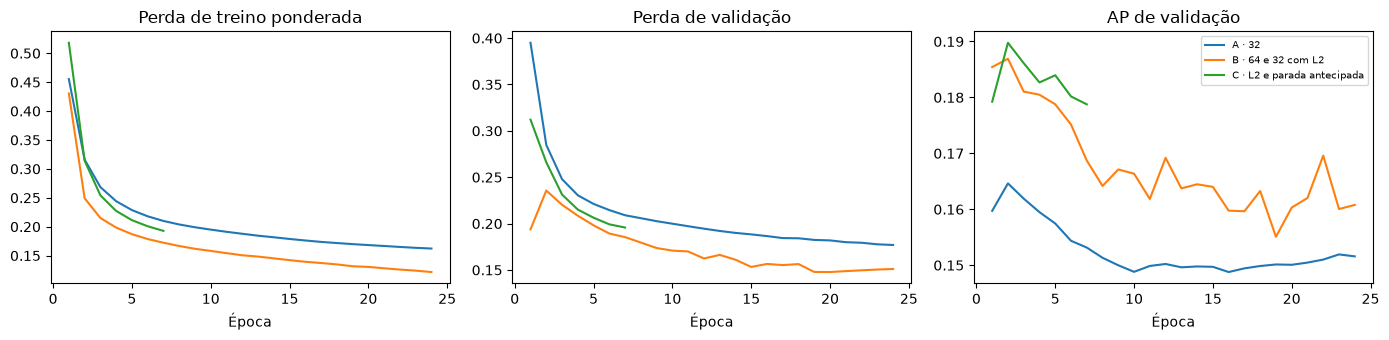

,configuracao,epoca,AP_validacao
0,A · 32,24,0.151581
1,B · 64 e 32 com L2,24,0.160778
2,C · L2 e parada antecipada,2,0.189765


Configuração escolhida: C · L2 e parada antecipada | Corte: 0.96137


In [3]:
prep = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
A = prep.fit_transform(Xtr)
V = prep.transform(Xv)
T = prep.transform(Xt)
weights = compute_sample_weight('balanced', ytr)
configs = {
    'A · 32': ((32,), 0.0001, 0.001, None),
    'B · 64 e 32 com L2': ((64, 32), 0.02, 0.001, None),
    'C · L2 e parada antecipada': ((64, 32), 0.02, 0.0005, 5),
}
runs = {}
curves = []
for name, (layers, alpha, lr, patience) in configs.items():
    model = MLPClassifier(hidden_layer_sizes=layers, alpha=alpha, batch_size=256,
                          learning_rate_init=lr, random_state=26)
    best_ap, best_epoch = -1, 0
    with threadpool_limits(limits=1):
        for epoch in range(1, 25):
            model.partial_fit(A, ytr, classes=[0, 1], sample_weight=weights)
            pv = model.predict_proba(V)[:, 1]
            ap = average_precision_score(yv, pv)
            curves.append(dict(modelo=name, epoca=epoch, perda_treino=model.loss_,
                               perda_validacao=log_loss(yv, pv), ap_validacao=ap))
            if ap > best_ap:
                best_ap, best_epoch = ap, epoch
                checkpoint = deepcopy(model)
            if patience and epoch - best_epoch >= patience:
                break
    if patience:
        model = checkpoint
    else:
        best_epoch = epoch
    runs[name] = (model, best_epoch, average_precision_score(yv, model.predict_proba(V)[:, 1]))
curves = pd.DataFrame(curves)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for name, group in curves.groupby('modelo', sort=False):
    for ax, col, title in zip(axes, ['perda_treino','perda_validacao','ap_validacao'],
                              ['Perda de treino ponderada','Perda de validação','AP de validação']):
        ax.plot(group.epoca, group[col], label=name)
        ax.set(title=title, xlabel='Época')
axes[-1].legend(fontsize=7)
plt.tight_layout()
plt.show()
comparison = pd.DataFrame([dict(configuracao=name, epoca=epoch, AP_validacao=ap)
                            for name, (_, epoch, ap) in runs.items()])
display(comparison)
winner = comparison.sort_values('AP_validacao', ascending=False).iloc[0].configuracao
model = runs[winner][0]
pv = model.predict_proba(V)[:, 1]
p, r, thresholds = precision_recall_curve(yv, pv)
f1s = np.divide(2*p[:-1]*r[:-1], p[:-1]+r[:-1], out=np.zeros(len(thresholds)), where=(p[:-1]+r[:-1])>0)
cutoff = float(thresholds[np.argmax(f1s)])
print('Configuração escolhida:', winner, '| Corte:', round(cutoff, 5))

## Avaliação final e demonstração funcional
Comparamos a rede escolhida com o resultado de ML em 2024. AP avalia a ordenação dos escores para uma classe rara. Precisão mede a proporção de alertas corretos e recall, a proporção de janelas positivas detectadas. Janelas sobrepostas podem corresponder ao mesmo episódio. O teste abaixo demonstra uma previsão com entrada, escore, corte, classe e precipitação posterior.

In [4]:
scores = model.predict_proba(T)[:, 1]
predicted = scores >= cutoff
prec, rec, f1, _ = precision_recall_fscore_support(yt, predicted, average='binary', zero_division=0)
tn, fp, fn, tp = [int(x) for x in confusion_matrix(yt, predicted, labels=[0, 1]).ravel()]
metrics = {'modelo':'MLP', 'AP':average_precision_score(yt, scores), 'precisao':prec,
           'recall':rec, 'F1':f1, 'TP':tp, 'FP':fp, 'FN':fn, 'TN':tn}
ml = pd.read_csv('dados/referencia-ml.csv')
ml_test = ml[ml.fase.eq('teste')].drop(columns='fase')
assert len(yt) == int(ml_test[['TP','FP','FN','TN']].iloc[0].sum())
display(pd.concat([ml_test, pd.DataFrame([metrics])], ignore_index=True).round(4))
out = []
for kind, mask in [('acerto positivo', predicted & yt.eq(1).to_numpy()),
                   ('falso aviso', predicted & yt.eq(0).to_numpy()),
                   ('janela perdida', ~predicted & yt.eq(1).to_numpy())]:
    ids = np.flatnonzero(mask)
    if not len(ids):
        continue
    i = ids[0]
    t = Xt.index[i]
    record = dict(caso=kind, emitido_em_utc=t.isoformat(), horizonte_h=HORIZON,
                  entrada={k: float(v) if pd.notna(v) else None for k,v in Xt.iloc[i].items()},
                  escore=float(scores[i]), corte=cutoff, classe_prevista=int(predicted[i]),
                  classe_observada=int(yt.iloc[i]), chuva_posterior_mm=round(float(future.loc[t]), 2))
    out.append(record)
    print(json.dumps(record, ensure_ascii=False, indent=2))
Path('reproducao-rn.json').write_text(json.dumps(dict(modo='reproducao_historica', fonte='ERA5 via Open-Meteo', modelo=winner, limiar_mm_3h=LIMIT, casos=out), ensure_ascii=False, indent=2), encoding='utf-8')
Path('resultados-rn.json').write_text(json.dumps(dict(configuracao=winner, metricas=metrics, comparacao=comparison.to_dict('records')),ensure_ascii=False,indent=2),encoding='utf-8')

,modelo,AP,precisao,recall,F1,FP,FN,TP,TN
0,Referência,0.0061,0.0000,0.0000,0.0000,0,54,0,8727
1,Regressão logística,0.1722,0.1944,0.2593,0.2222,58,40,14,8669
2,Random Forest,0.1422,0.1049,0.5185,0.1745,239,26,28,8488
3,MLP,0.1586,0.1724,0.2778,0.2128,72,39,15,8655


{
  "caso": "acerto positivo",
  "emitido_em_utc": "2024-01-23T15:00:00+00:00",
  "horizonte_h": 3,
  "entrada": {
    "chuva_1h": 3.5,
    "temperature_2m": 19.1,
    "relative_humidity_2m": 94.0,
    "surface_pressure": 931.6,
    "chuva_3h": 6.800000000000006,
    "chuva_6h": 11.100000000000017,
    "chuva_24h": 13.3,
    "variacao_pressao_3h": 0.39999999999997726,
    "hora_sen": -0.7071067811865471,
    "hora_cos": -0.7071067811865479,
    "mes_sen": 0.0,
    "mes_cos": 1.0
  },
  "escore": 0.9670358039117612,
  "corte": 0.9613683061395327,
  "classe_prevista": 1,
  "classe_observada": 1,
  "chuva_posterior_mm": 10.7
}
{
  "caso": "falso aviso",
  "emitido_em_utc": "2024-01-03T17:00:00+00:00",
  "horizonte_h": 3,
  "entrada": {
    "chuva_1h": 5.3,
    "temperature_2m": 26.0,
    "relative_humidity_2m": 73.0,
    "surface_pressure": 927.3,
    "chuva_3h": 6.400000000000004,
    "chuva_6h": 6.700000000000019,
    "chuva_24h": 7.600000000000002,
    "variacao_pressao_3h": -2.6000000

650

### Inferência em uma janela inédita
Executamos a rede selecionada em uma única linha do teste e conferimos a saída com a precipitação das três horas seguintes.

In [5]:
janela = pd.Timestamp('2024-01-23T15:00:00Z')
entrada = Xt.loc[[janela]]
escore = float(model.predict_proba(prep.transform(entrada))[0, 1])
classe = int(escore >= cutoff)
display(entrada.round(3))
display(pd.DataFrame([{'escore': round(escore, 4), 'corte': round(cutoff, 4),
                       'classe_prevista': classe, 'classe_observada': int(yt.loc[janela]),
                       'chuva_posterior_mm': round(float(future.loc[janela]), 2)}]))
assert np.isclose(escore, scores[Xt.index.get_loc(janela)])

,chuva_1h,temperature_2m,relative_humidity_2m,surface_pressure,chuva_3h,chuva_6h,chuva_24h,variacao_pressao_3h,hora_sen,hora_cos,mes_sen,mes_cos
time,,,,,,,,,,,,
2024-01-23 15:00:00+00:00,3.5,19.1,94,931.6,6.8,11.1,13.3,0.4,-0.707,-0.707,0.0,1.0


,escore,corte,classe_prevista,classe_observada,chuva_posterior_mm
0,0.967,0.9614,1,1,10.7


## Interpretação dos resultados
A configuração C foi escolhida com AP de validação de 0,190, acima de A (0,152) e B (0,161). O checkpoint usado veio da segunda época. A comparação varia mais de um fator entre configurações, então ela indica qual configuração conjunta funcionou melhor neste recorte. O experimento não isola o ganho de cada hiperparâmetro.

No mesmo teste de 2024, a rede obteve AP de 0,159, precisão de 17,2% e recall de 27,8%. Identificou 15 de 54 janelas positivas e gerou 72 falsos avisos. A regressão logística obteve AP de 0,172, identificou 14 janelas e gerou 58 falsos avisos. Na comparação, a rede identificou uma janela positiva a mais e produziu 14 falsos avisos adicionais. A regressão logística teve maior AP neste teste.

## Integração com o VIGIA
A demonstração exporta três previsões históricas em `reproducao-rn.json`. Cada caso inclui horário, horizonte, entradas, classe prevista e acumulado posterior da reanálise. Esses campos permitem apresentar a previsão junto das medições de nível do VIGIA, com origem e unidades explícitas em texto. A avaliação descreve chuva regional e mantém separados o resultado do modelo e o aviso local acionado pela estação.

## Adequação dos dados, limitações e evolução
A base contém variáveis meteorológicas estruturadas e um histórico horário extenso, adequado a uma MLP tabular. A mesma fonte e as mesmas fronteiras de ML permitem comparar os modelos no mesmo período. A preparação apresenta exemplos e a contagem de ausências. A engenharia de atributos resume o histórico disponível até cada emissão.

A configuração C usa o checkpoint da segunda época. A parada antecipada evita continuar o treinamento após a perda de desempenho na validação. As curvas permitem acompanhar esse comportamento. A AP passa de 0,190 na validação para 0,159 no teste, indicando sensibilidade ao período avaliado. As perdas de treino ponderada e validação sem ponderação usam pesos diferentes e devem ser interpretadas com essa diferença. Os dados são desbalanceados e janelas sobrepostas têm dependência temporal. Ruído, imprecisão da reanálise e sua resolução regional podem afetar o alvo e as entradas. Não isolamos o efeito de cada hiperparâmetro nas três configurações.

O JSON demonstra a integração por reprodução histórica. O encaminhamento automático para o painel e a integração em tempo real com sensores são evoluções futuras. Antes do uso operacional, são necessários dados locais, avaliação da disponibilidade das entradas no instante de emissão e uma política de decisão validada com responsáveis pelo monitoramento. Os falsos avisos e as ocorrências perdidas limitam o uso do resultado para decisões sobre uma travessia.

A base meteorológica dispensa dados pessoais dos moradores. Uma integração deve validar as mensagens, controlar o acesso e identificar a origem das medições. O painel deve apresentar estados também em texto, com unidade e horário, para apoiar a acessibilidade. A proposta se relaciona aos ODS 11 e 13 pela informação local e adaptação a eventos de chuva. O treinamento em base tabular e a comparação de arquiteturas pequenas mantêm o custo computacional limitado ao experimento.